### 1. Random Forest Classifier — Baseline Model

Random Forest is a supervised machine learning algorithm used for classification and regression tasks. In this project, a Random Forest Classifier is implemented to identify potentially fraudulent orders based on historical order information.

The model performs binary classification, where:
- **0:** Legitimate order
- **1:** Fraudulent order

Random Forest is an ensemble learning algorithm that combines multiple decision trees to generate predictions. Each decision tree learns different patterns from the training dataset, and the final classification is determined by aggregating the predictions of the individual trees.

Random Forest was selected because it can capture complex, non-linear relationships between order characteristics and fraudulent activities. It is also suitable for datasets containing multiple numerical and categorical features.

### How did we account for the imbalanced data? ( 89% legitimate orders and 11% fraudulent orders )
Five-Fold Stratified Cross-Validation was implemented to evaluate the Random Forest Classifier's performance and consistency across different subsets of the training data.

The dataset was first divided into 70% training, 15% validation and 15% testing. Cross-validation was performed exclusively on the 70% training dataset to prevent information leakage from the validation and testing datasets. This ensures that each training and internal validation subset contains a representative distribution of both classes.

-------

#### Training of Baseline Random Forest -- Results Analysis

In [7]:
pip install pandas numpy scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

# Load processed dataset
df = pd.read_csv("base_processed.csv")

print("Dataset shape:", df.shape)
print(df.head())

# Check fraud distribution
print("\nFraud distribution:")
print(df["is_fraud"].value_counts())
print(df["is_fraud"].value_counts(normalize=True))


Dataset shape: (949872, 12)
  country_code    order_id customer_id  order_date collect_type  \
0           TH  b9ce4cdead  4a2deee064  2022-12-31     delivery   
1           MY  eae640c3dd  0e39f85e6d  2023-03-27     delivery   
2           PH  6b5eff4d8f  b88034bb7a  2022-11-16     delivery   
3           MY  31928238a7  b24be37d24  2023-01-02     delivery   
4           MY  4adec8e335  996287540f  2023-04-02     delivery   

        payment_method  order_value  num_items_ordered  is_fraud  \
0  payment on delivery    13.877272                1.0         0   
1         boost wallet     2.512021                1.0         0   
2  payment on delivery     4.309368                3.0         0   
3          credit card     8.090340                1.0         0   
4              Unknown     8.934508                2.0         0   

   days_since_first_order  value_per_item order_weekday  
0                  1250.0       13.877272      Saturday  
1                     8.0        2.512021   

In [9]:
# Define features (X) and target (y)

features = [
    "country_code",
    "collect_type",
    "payment_method",
    "order_value",
    "num_items_ordered",
    "days_since_first_order",
    "value_per_item",
    "order_weekday"
]

X = df[features]
y = df["is_fraud"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (949872, 8)
y shape: (949872,)


In [10]:
# First split: 70% training, 30% remaining
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: 15% validation, 15% testing
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training size:", len(X_train))
print("Validation size:", len(X_val))
print("Testing size:", len(X_test))

print("\nTraining fraud ratio:", y_train.mean())
print("Validation fraud ratio:", y_val.mean())


Training size: 664910
Validation size: 142481
Testing size: 142481

Training fraud ratio: 0.10993217127129988
Validation fraud ratio: 0.10993746534625669


In [13]:
# Define numerical features
numerical_features = [
    "order_value",
    "num_items_ordered",
    "days_since_first_order",
    "value_per_item"
]

# Define categorical features
categorical_features = [
    "country_code",
    "collect_type",
    "payment_method",
    "order_weekday"
]

In [14]:
# Numerical preprocessing
numerical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("onehot", OneHotEncoder(
        handle_unknown="ignore"
    ))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)


In [15]:

# Random Forest classifier
rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Combine preprocessing and model
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", rf)
])


In [ ]:
# Define Stratified K-Fold
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Evaluation metrics
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

# Cross-validation on training data ONLY
cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=1
)

# Display results
print("\n===== 5-FOLD CROSS-VALIDATION RESULTS =====")

for metric in scoring:
    scores = cv_results["test_" + metric]

    print(f"\n{metric.upper()}")
    print("Fold scores:", np.round(scores, 4))
    print(f"Mean: {scores.mean():.4f}")
    print(f"Std: {scores.std():.4f}")



===== 5-FOLD CROSS-VALIDATION RESULTS =====

ACCURACY
Fold scores: [0.8151 0.8154 0.8169 0.8145 0.8148]
Mean: 0.8153
Std: 0.0008

PRECISION
Fold scores: [0.332  0.3328 0.3354 0.3306 0.3312]
Mean: 0.3324
Std: 0.0017

RECALL
Fold scores: [0.6732 0.6755 0.6783 0.6712 0.6713]
Mean: 0.6739
Std: 0.0027

F1
Fold scores: [0.4447 0.4459 0.4488 0.443  0.4435]
Mean: 0.4452
Std: 0.0021


In [17]:

# Train model using entire training dataset
model.fit(X_train, y_train)

print("Random Forest training completed!")


Random Forest training completed!


In [18]:

# Predict validation dataset
y_val_pred = model.predict(X_val)

# Calculate evaluation metrics
accuracy = accuracy_score(y_val, y_val_pred)
precision = precision_score(
    y_val, y_val_pred, zero_division=0
)
recall = recall_score(
    y_val, y_val_pred, zero_division=0
)
f1 = f1_score(
    y_val, y_val_pred, zero_division=0
)

print("\n===== VALIDATION RESULTS =====")
print(f"Accuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1 Score:  {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))



===== VALIDATION RESULTS =====
Accuracy:  0.8147
Precision: 0.3328
Recall:    0.6823
F1 Score:  0.4474

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.95      0.83      0.89    126817
       Fraud       0.33      0.68      0.45     15664

    accuracy                           0.81    142481
   macro avg       0.64      0.76      0.67    142481
weighted avg       0.89      0.81      0.84    142481



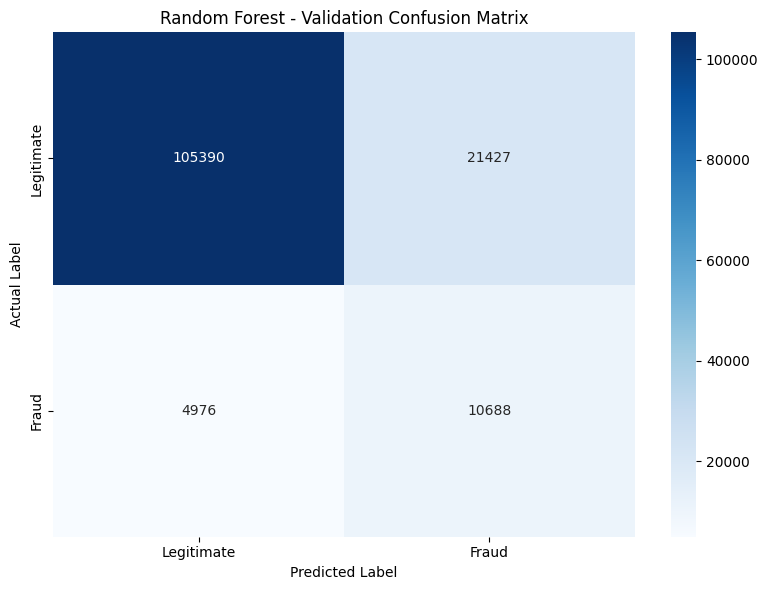

In [19]:

# Calculate confusion matrix
cm = confusion_matrix(
    y_val,
    y_val_pred,
    labels=[0, 1]
)

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Random Forest - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()


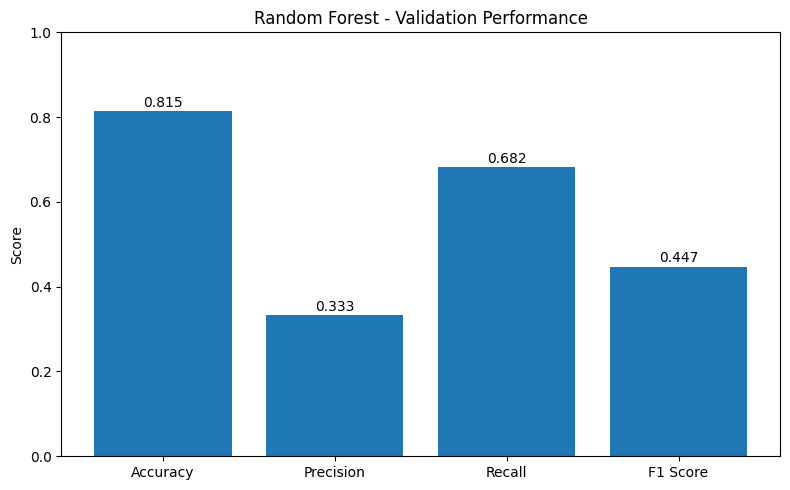

In [ ]:
metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics.keys(),
    metrics.values()
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Random Forest - Validation Performance")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


### Analysis of results and performance of the model
The baseline Random Forest demonstrated moderate classification performance, with an accuracy of 80+% and a recall of ~68%. However, its relatively low precision which indicates that the model frequently misclassified legitimate orders as fraudulent.

The confusion matrix further highlights the model's difficulty in distinguishing between legitimate and fraudulent transactions, resulting in both false-positive and false-negative predictions.

Overall, the baseline model provides a useful starting point but has limitations in classification accuracy and reliability, particularly when handling an imbalanced dataset.

Identified Limitation: The baseline model detects a substantial proportion of fraudulent orders but produces many false positives. Therefore, targeted hyperparameter tuning is introduced to improve precision and F1-score while attempting to maintain fraud recall.

-----------

### Tuning methedology and Justifications 
Based on the baseline evaluation, the main weakness identified was the high number of false-positive predictions, resulting in low precision. To address this limitation, 


#### Parameters for random forest: 
- n_estimators : Tests different numbers of trees to balance predictive stability and computational cost.
- max_depth : Controls how deeply trees can grow, helping manage overfitting.
- min_samples_split : Controls the minimum number of observations needed to split a node. 
- min_samples_leaf : Prevents overly specific decision rules based on very small groups of orders.
- max_features : Controls the number of features considered at each split, increasing diversity between trees.
- class_weight : Adjusts the relative importance of legitimate and fraudulent orders.


Randomized Search was used to determin the best parameters that would give the best performance results, four randomly selected hyperparameter combinations were evaluated using Five-Fold Stratified Cross-Validation. 


In [36]:

# =====================================================
# TUNED RANDOM FOREST - MODEL SETUP
# =====================================================

from sklearn.base import clone
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline

# Create tuned Random Forest
rf_tuned = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

# Create tuned pipeline
model_tuned = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("classifier", rf_tuned)
])

# Hyperparameter search space
param_grid_tuned = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [10, 15, 20, 25],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [2, 5, 10],
    "classifier__max_features": ["sqrt", 0.5],
    "classifier__class_weight": [
        "balanced",
        "balanced_subsample",
        {0: 1, 1: 3},
        {0: 1, 1: 5}
    ]
}

print("Tuned Random Forest pipeline created!")


Tuned Random Forest pipeline created!


In [37]:
# =====================================================
# BASELINE CROSS-VALIDATION REFERENCE
# =====================================================

# Uses cv_results from your existing baseline code
baseline_cv = {
    metric: cv_results["test_" + metric].mean()
    for metric in scoring
}

print("\n===== BASELINE 5-FOLD CV REFERENCE =====")

for metric, value in baseline_cv.items():
    print(f"{metric.upper()}: {value:.4f}")



===== BASELINE 5-FOLD CV REFERENCE =====
ACCURACY: 0.8153
PRECISION: 0.3324
RECALL: 0.6739
F1: 0.4452


In [38]:

# =====================================================
# TUNED RF - MULTI-METRIC RANDOMIZED SEARCH
# =====================================================

import numpy as np
from sklearn.model_selection import RandomizedSearchCV

metric_names = ["accuracy", "precision", "recall", "f1"]

def select_best_model(cv_results_search):

    # Extract cross-validation scores
    scores = np.column_stack([
        cv_results_search["mean_test_" + metric]
        for metric in metric_names
    ])

    baseline_scores = np.array([
        baseline_cv[metric]
        for metric in metric_names
    ])

    # Difference relative to baseline CV
    differences = scores - baseline_scores

    # Check candidates that improve ALL four metrics
    all_improved = np.all(differences > 0, axis=1)

    if np.any(all_improved):

        # Among candidates improving all metrics,
        # choose the one with the highest F1
        eligible = np.where(all_improved)[0]

        best_index = eligible[
            np.argmax(scores[eligible, 3])
        ]

        print(
            "Found candidate improving all four "
            "cross-validation metrics."
        )

    else:

        # No candidate improved all metrics
        # Choose strongest worst-metric improvement
        relative_changes = differences / np.maximum(
            baseline_scores, 1e-8
        )

        worst_changes = relative_changes.min(axis=1)

        best_index = int(np.argmax(worst_changes))

        print(
            "No candidate improved all four metrics."
        )
        print(
            "Selecting the strongest compromise."
        )

    return int(best_index)


random_search_tuned = RandomizedSearchCV(
    estimator=model_tuned,
    param_distributions=param_grid_tuned,
    n_iter=4,                 # Reduced from 20 to 4
    scoring=scoring,
    cv=skf,                  # Keep 5-Fold CV
    refit=select_best_model,
    random_state=42,
    n_jobs=1,
    verbose=2,
    error_score="raise"
)

# Train using ONLY the 70% training dataset
random_search_tuned.fit(X_train, y_train)

# Retrieve best trained model
model_tuned = random_search_tuned.best_estimator_

# Retrieve tuned Random Forest
rf_tuned = model_tuned.named_steps["classifier"]

print("\n===== TUNED RANDOM FOREST =====")

print("\nBest Hyperparameters:")
for parameter, value in random_search_tuned.best_params_.items():
    print(f"{parameter}: {value}")

print("\nHyperparameter tuning completed!")

Fitting 5 folds for each of 4 candidates, totalling 20 fits
[CV] END classifier__class_weight=balanced, classifier__max_depth=20, classifier__max_features=0.5, classifier__min_samples_leaf=10, classifier__min_samples_split=2, classifier__n_estimators=50; total time=  37.0s
[CV] END classifier__class_weight=balanced, classifier__max_depth=20, classifier__max_features=0.5, classifier__min_samples_leaf=10, classifier__min_samples_split=2, classifier__n_estimators=50; total time=  50.6s
[CV] END classifier__class_weight=balanced, classifier__max_depth=20, classifier__max_features=0.5, classifier__min_samples_leaf=10, classifier__min_samples_split=2, classifier__n_estimators=50; total time=  58.4s
[CV] END classifier__class_weight=balanced, classifier__max_depth=20, classifier__max_features=0.5, classifier__min_samples_leaf=10, classifier__min_samples_split=2, classifier__n_estimators=50; total time=  57.6s
[CV] END classifier__class_weight=balanced, classifier__max_depth=20, classifier__ma

In [39]:

# =====================================================
# TUNED RF - 5-FOLD CROSS-VALIDATION
# =====================================================

# Cross-validation on training data ONLY
cv_results_tuned = cross_validate(
    model_tuned,
    X_train,
    y_train,
    cv=skf,
    scoring=scoring,
    n_jobs=1
)

# Display results - SAME FORMAT AS BASELINE
print("\n===== TUNED RF 5-FOLD CROSS-VALIDATION RESULTS =====")

for metric in scoring:
    scores = cv_results_tuned["test_" + metric]

    print(f"\n{metric.upper()}")
    print("Fold scores:", np.round(scores, 4))
    print(f"Mean: {scores.mean():.4f}")
    print(f"Std: {scores.std():.4f}")



===== TUNED RF 5-FOLD CROSS-VALIDATION RESULTS =====

ACCURACY
Fold scores: [0.8188 0.8193 0.8206 0.8174 0.8176]
Mean: 0.8187
Std: 0.0012

PRECISION
Fold scores: [0.3359 0.338  0.3402 0.3337 0.335 ]
Mean: 0.3366
Std: 0.0023

RECALL
Fold scores: [0.664  0.6718 0.6724 0.6631 0.6692]
Mean: 0.6681
Std: 0.0039

F1
Fold scores: [0.4462 0.4497 0.4518 0.4439 0.4465]
Mean: 0.4476
Std: 0.0028


In [40]:

# =====================================================
# TUNED RF - FINAL TRAINING CONFIRMATION
# =====================================================

# model_tuned is already fitted on X_train, y_train
# by RandomizedSearchCV(refit=select_best_model).

print("Tuned Random Forest training completed!")
print("Number of trees:", rf_tuned.n_estimators)
print("Maximum depth:", rf_tuned.max_depth)
print("Minimum samples per leaf:", rf_tuned.min_samples_leaf)
print("Class weight:", rf_tuned.class_weight)


Tuned Random Forest training completed!
Number of trees: 50
Maximum depth: 20
Minimum samples per leaf: 10
Class weight: balanced


In [41]:

# =====================================================
# TUNED RF - VALIDATION EVALUATION
# =====================================================

# Predict validation dataset
y_val_pred_tuned = model_tuned.predict(X_val)

# Calculate evaluation metrics
accuracy_tuned = accuracy_score(
    y_val, y_val_pred_tuned
)

precision_tuned = precision_score(
    y_val, y_val_pred_tuned,
    zero_division=0
)

recall_tuned = recall_score(
    y_val, y_val_pred_tuned,
    zero_division=0
)

f1_tuned = f1_score(
    y_val, y_val_pred_tuned,
    zero_division=0
)

print("\n===== TUNED RF VALIDATION RESULTS =====")
print(f"Accuracy:  {accuracy_tuned:.4f}")
print(f"Precision: {precision_tuned:.4f}")
print(f"Recall:    {recall_tuned:.4f}")
print(f"F1 Score:  {f1_tuned:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_val_pred_tuned,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))



===== TUNED RF VALIDATION RESULTS =====
Accuracy:  0.8181
Precision: 0.3368
Recall:    0.6759
F1 Score:  0.4496

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.95      0.84      0.89    126817
       Fraud       0.34      0.68      0.45     15664

    accuracy                           0.82    142481
   macro avg       0.65      0.76      0.67    142481
weighted avg       0.89      0.82      0.84    142481



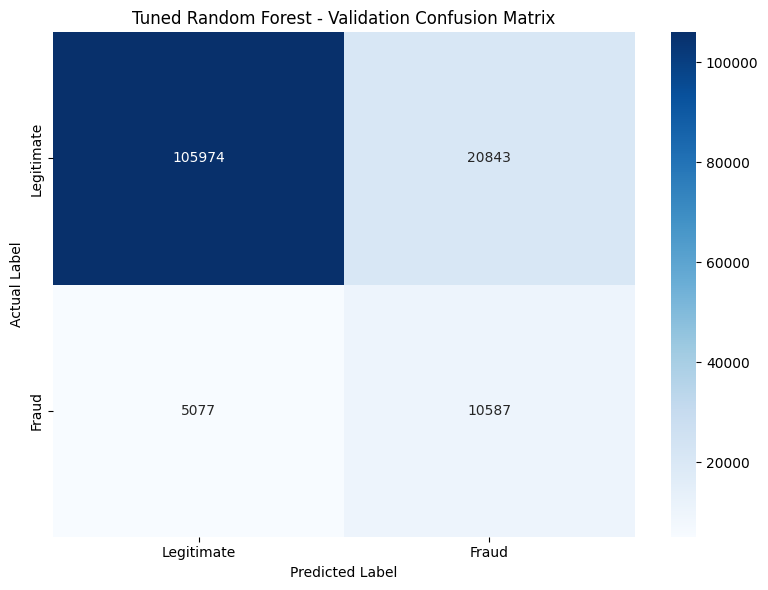


===== TUNED RF CONFUSION MATRIX =====
True Negatives: 105974
False Positives: 20843
False Negatives: 5077
True Positives: 10587


In [42]:

# =====================================================
# TUNED RF - CONFUSION MATRIX
# =====================================================

cm_tuned = confusion_matrix(
    y_val,
    y_val_pred_tuned,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_tuned,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Tuned Random Forest - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

# Print confusion matrix values
tn_tuned, fp_tuned, fn_tuned, tp_tuned = cm_tuned.ravel()

print("\n===== TUNED RF CONFUSION MATRIX =====")
print("True Negatives:", tn_tuned)
print("False Positives:", fp_tuned)
print("False Negatives:", fn_tuned)
print("True Positives:", tp_tuned)


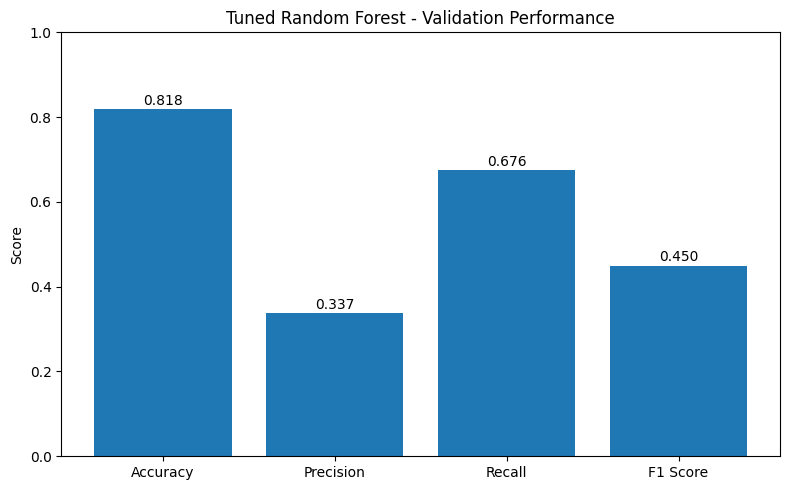

In [43]:

# =====================================================
# TUNED RF - VALIDATION PERFORMANCE CHART
# =====================================================

metrics_tuned = {
    "Accuracy": accuracy_tuned,
    "Precision": precision_tuned,
    "Recall": recall_tuned,
    "F1 Score": f1_tuned
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics_tuned.keys(),
    metrics_tuned.values()
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Tuned Random Forest - Validation Performance")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


### Tunned Random Forest Evaluation: 
The tuned model achieved improvements in accuracy, precision and F1-score compared with baseline. 
Hyperparameter tuning produced a modest improvement in precision and F1-score, but this came at the expense of slightly lower recall. Therefore, the tuned model did not achieve simultaneous improvement across all four evaluation metrics.


===== BASELINE VS TUNED RF =====
           Baseline RF  Tuned RF  Difference
Accuracy        0.8147    0.8181      0.0034
Precision       0.3328    0.3368      0.0040
Recall          0.6823    0.6759     -0.0064
F1 Score        0.4474    0.4496      0.0022

===== IMPROVEMENT CHECK =====
Accuracy: IMPROVED (+0.0034)
Precision: IMPROVED (+0.0040)
Recall: DECREASED (-0.0064)
F1 Score: IMPROVED (+0.0022)


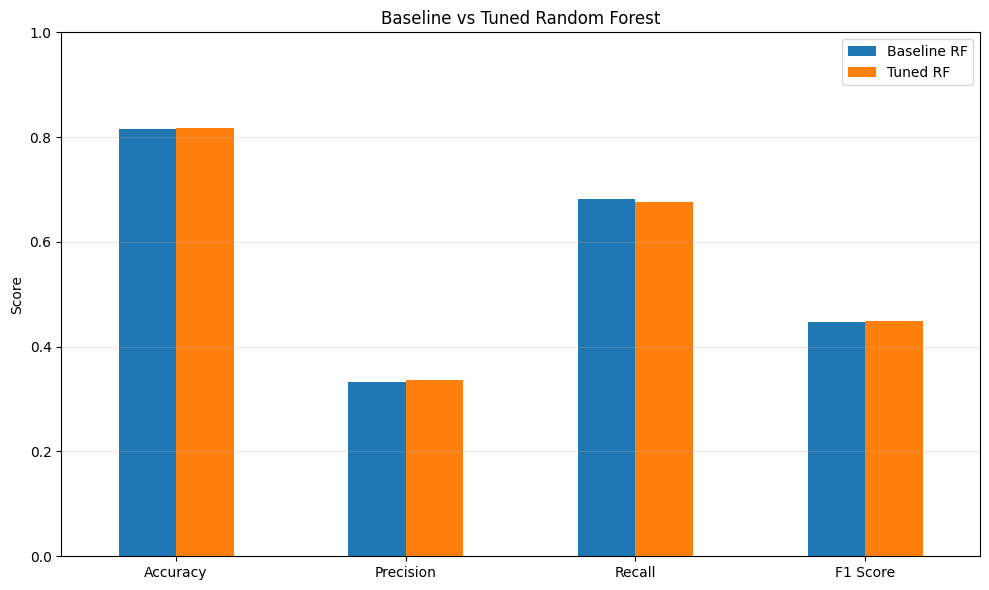

In [46]:

# =====================================================
# BASELINE VS TUNED RANDOM FOREST
# =====================================================

# Baseline metrics from your existing model
baseline_metrics = {
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1 Score": f1
}

# Tuned model metrics
tuned_metrics = {
    "Accuracy": accuracy_tuned,
    "Precision": precision_tuned,
    "Recall": recall_tuned,
    "F1 Score": f1_tuned
}

# Create comparison table
comparison_tuned = pd.DataFrame({
    "Baseline RF": baseline_metrics,
    "Tuned RF": tuned_metrics
})

comparison_tuned["Difference"] = (
    comparison_tuned["Tuned RF"]
    - comparison_tuned["Baseline RF"]
)

print("\n===== BASELINE VS TUNED RF =====")
print(comparison_tuned.round(4))

# Check each metric
print("\n===== IMPROVEMENT CHECK =====")

for metric in baseline_metrics:
    difference = comparison_tuned.loc[metric, "Difference"]

    if difference > 0:
        status = "IMPROVED"
    elif difference < 0:
        status = "DECREASED"
    else:
        status = "UNCHANGED"

    print(f"{metric}: {status} ({difference:+.4f})")

# Check if ALL metrics improved
all_improved = (
    comparison_tuned["Difference"] > 0
).all()


# Plot comparison
comparison_tuned[
    ["Baseline RF", "Tuned RF"]
].plot(
    kind="bar",
    figsize=(10, 6),
    rot=0
)

plt.title("Baseline vs Tuned Random Forest")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [45]:

# =====================================================
# BASELINE VS TUNED RF - CONFUSION MATRIX COMPARISON
# =====================================================

cm_baseline = confusion_matrix(
    y_val,
    model.predict(X_val),
    labels=[0, 1]
)

tn_base, fp_base, fn_base, tp_base = cm_baseline.ravel()

confusion_comparison = pd.DataFrame({
    "Baseline RF": [tn_base, fp_base, fn_base, tp_base],
    "Tuned RF": [
        tn_tuned, fp_tuned, fn_tuned, tp_tuned
    ]
}, index=[
    "True Negatives",
    "False Positives",
    "False Negatives",
    "True Positives"
])

confusion_comparison["Difference"] = (
    confusion_comparison["Tuned RF"]
    - confusion_comparison["Baseline RF"]
)

print("\n===== CONFUSION MATRIX COMPARISON =====")
print(confusion_comparison)



===== CONFUSION MATRIX COMPARISON =====
                 Baseline RF  Tuned RF  Difference
True Negatives        105390    105974         584
False Positives        21427     20843        -584
False Negatives         4976      5077         101
True Positives         10688     10587        -101


### Final Evaluation: Baseline vs Tuned Random Forest

Overall, the tuned Random Forest demonstrated modest improvements over the baseline model in terms of accuracy, precision and F1-score. The reduction in false-positive predictions indicates that the tuned model was more effective at correctly identifying legitimate orders, although this improvement came with a slight decrease in recall, resulting in more fraudulent orders being missed. Despite this trade-off, the tuned model achieved a better balance between precision and recall, as reflected by its improved F1-score. Furthermore, the tuned model demonstrated consistent performance across cross-validation, validation and testing, with only minor differences between validation and testing results. This suggests that the model generalizes reasonably well to unseen data, with no clear evidence of significant overfitting

In [51]:

# =====================================================
# TUNED RANDOM FOREST - TESTING EVALUATION
# =====================================================

# Predict testing dataset
y_test_pred_tuned = model_tuned.predict(X_test)

# Calculate evaluation metrics
accuracy_test = accuracy_score(
    y_test, y_test_pred_tuned
)

precision_test = precision_score(
    y_test, y_test_pred_tuned,
    zero_division=0
)

recall_test = recall_score(
    y_test, y_test_pred_tuned,
    zero_division=0
)

f1_test = f1_score(
    y_test, y_test_pred_tuned,
    zero_division=0
)

print("\n===== TUNED RF TESTING RESULTS =====")
print(f"Accuracy:  {accuracy_test:.4f}")
print(f"Precision: {precision_test:.4f}")
print(f"Recall:    {recall_test:.4f}")
print(f"F1 Score:  {f1_test:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_test_pred_tuned,
    target_names=["Legitimate", "Fraud"],
    zero_division=0
))



===== TUNED RF TESTING RESULTS =====
Accuracy:  0.8153
Precision: 0.3326
Recall:    0.6755
F1 Score:  0.4457

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.95      0.83      0.89    126818
       Fraud       0.33      0.68      0.45     15663

    accuracy                           0.82    142481
   macro avg       0.64      0.75      0.67    142481
weighted avg       0.89      0.82      0.84    142481



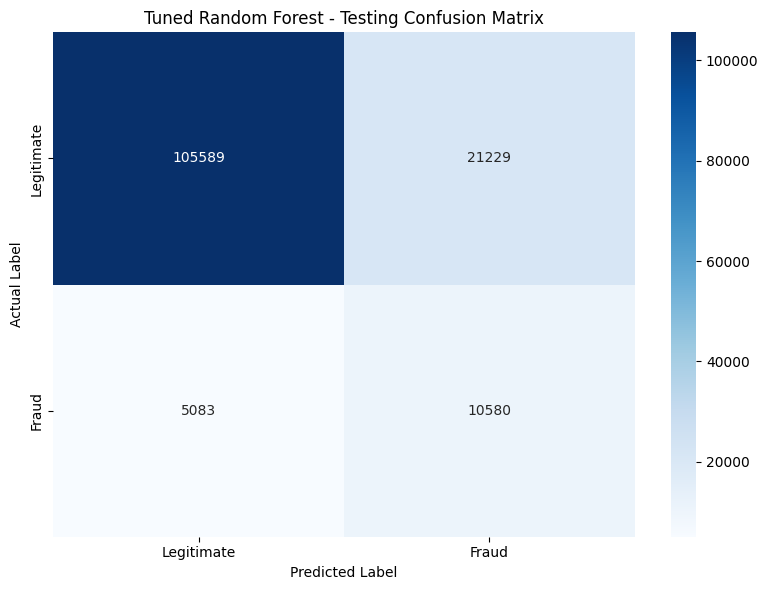


===== TESTING CONFUSION MATRIX =====
True Negatives: 105589
False Positives: 21229
False Negatives: 5083
True Positives: 10580


In [48]:

# =====================================================
# TUNED RF - TESTING CONFUSION MATRIX
# =====================================================

cm_test = confusion_matrix(
    y_test,
    y_test_pred_tuned,
    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_test,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Legitimate", "Fraud"],
    yticklabels=["Legitimate", "Fraud"]
)

plt.title("Tuned Random Forest - Testing Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.tight_layout()
plt.show()

# Extract confusion matrix values
tn_test, fp_test, fn_test, tp_test = cm_test.ravel()

print("\n===== TESTING CONFUSION MATRIX =====")
print("True Negatives:", tn_test)
print("False Positives:", fp_test)
print("False Negatives:", fn_test)
print("True Positives:", tp_test)


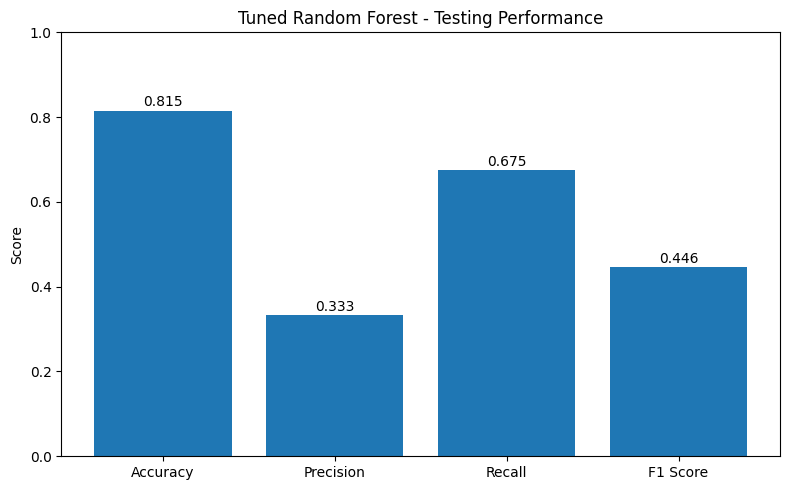

In [49]:

# =====================================================
# TUNED RF - TESTING PERFORMANCE CHART
# =====================================================

metrics_test = {
    "Accuracy": accuracy_test,
    "Precision": precision_test,
    "Recall": recall_test,
    "F1 Score": f1_test
}

plt.figure(figsize=(8, 5))

bars = plt.bar(
    metrics_test.keys(),
    metrics_test.values()
)

plt.ylim(0, 1)
plt.ylabel("Score")
plt.title("Tuned Random Forest - Testing Performance")

for bar in bars:
    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height:.3f}",
        ha="center"
    )

plt.tight_layout()
plt.show()



===== VALIDATION VS TESTING =====
           Validation  Testing  Difference
Accuracy       0.8181   0.8153     -0.0028
Precision      0.3368   0.3326     -0.0042
Recall         0.6759   0.6755     -0.0004
F1 Score       0.4496   0.4457     -0.0039


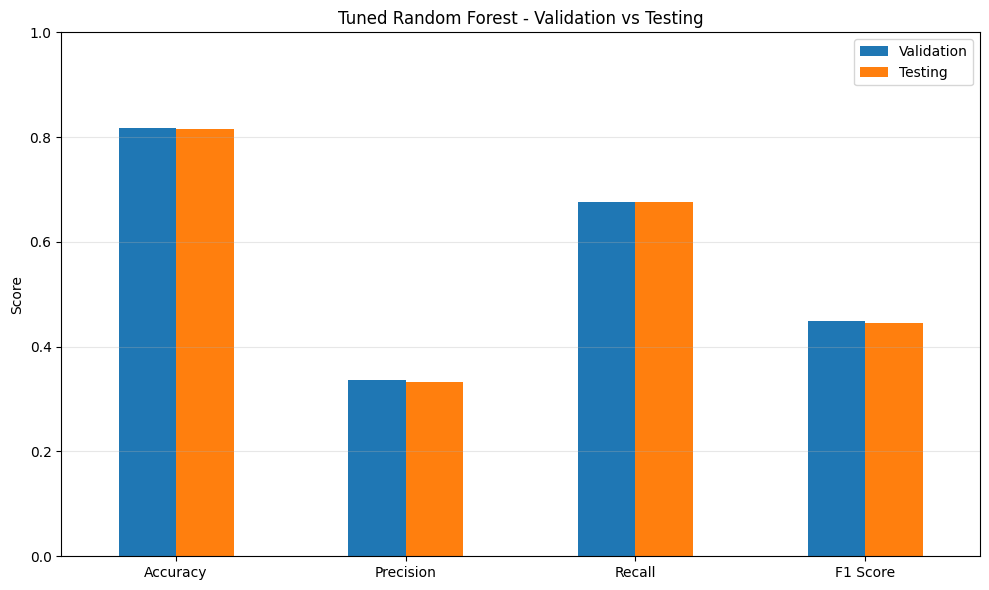

In [50]:

# =====================================================
# TUNED RF - VALIDATION VS TESTING
# =====================================================

comparison_test = pd.DataFrame({
    "Validation": {
        "Accuracy": accuracy_tuned,
        "Precision": precision_tuned,
        "Recall": recall_tuned,
        "F1 Score": f1_tuned
    },
    "Testing": {
        "Accuracy": accuracy_test,
        "Precision": precision_test,
        "Recall": recall_test,
        "F1 Score": f1_test
    }
})

comparison_test["Difference"] = (
    comparison_test["Testing"]
    - comparison_test["Validation"]
)

print("\n===== VALIDATION VS TESTING =====")
print(comparison_test.round(4))

# Plot comparison
comparison_test[
    ["Validation", "Testing"]
].plot(
    kind="bar",
    figsize=(10, 6),
    rot=0
)

plt.title("Tuned Random Forest - Validation vs Testing")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


 ### Final Testing Evaluation — Tuned Random Forest
 The tuned Random Forest was evaluated using the previously unseen testing dataset to assess its ability to generalize to new observations. The model achieved an accuracy of 81.53%, precision of 33.26%, recall of 67.55%, and F1-score of 44.57%. The confusion matrix shows that the model successfully identified a substantial proportion of fraudulent orders while correctly classifying most legitimate orders. Comparing the validation and testing results, all four evaluation metrics remained relatively consistent, with only minor decreases in testing performance. This suggests that the model generalizes reasonably well to unseen data, with no clear evidence of significant overfitting under the current evaluation approach.